In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# =========================
# Config
# =========================
FILES = {
    "SARIMA": Path("metrics/metrics_sarima.csv"),
    "GRU": Path("metrics/metrics_gru.csv"),
    "LSTM": Path("metrics/metrics_lstm.csv"),
    "PROPOSAL": Path("metrics/metrics_proposal.csv"),
}

# Renomear modelo PROPOSAL no gráfico
MODEL_DISPLAY = {
    "SARIMA": "SARIMA",
    "GRU": "GRU",
    "LSTM": "LSTM",
    "PROPOSAL": "Slicing-Window Based Prediction",  # como você pediu
}

# Métricas a plotar: coluna no CSV -> rótulo no gráfico
METRICS = {
    "smape": "SMAPE",
    "mae": "MAE",
    "correncapa": "Kappa de Cohen",   # renomear no gráfico
    "rmse": "RMSE",
}

OUTDIR = Path("./figures_metrics_cfp")
OUTDIR.mkdir(parents=True, exist_ok=True)

# Paleta "terrosa" (cores terrosas)
EARTHY = [
    "#7F4F24",  # marrom
    "#A68A64",  # areia
    "#6B705C",  # oliva acinzentado
    "#CB997E",  # terracota clara
]

DPI = 300

# =========================
# Load + merge
# =========================
dfs = []
for model, fp in FILES.items():
    if not fp.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {fp.resolve()}")

    d = pd.read_csv(fp)
    d.columns = [c.strip().lower() for c in d.columns]

    # Checagens mínimas
    required = {"link", "protocol"} | set(METRICS.keys())
    missing = required - set(d.columns)
    if missing:
        raise ValueError(f"No arquivo {fp.name} faltam colunas: {sorted(missing)}")

    d["model"] = model
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)

# Garantir tipos numéricos nas métricas
for col in METRICS.keys():
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=list(METRICS.keys())).copy()
df["model_display"] = df["model"].map(MODEL_DISPLAY).fillna(df["model"])

# Ordenação consistente nos gráficos
model_order = [MODEL_DISPLAY[m] for m in ["SARIMA", "GRU", "LSTM", "PROPOSAL"]]
df["model_display"] = pd.Categorical(df["model_display"], categories=model_order, ordered=True)

# =========================
# Helpers
# =========================
def boxplot_metric(data: pd.DataFrame, metric_col: str, metric_label: str, outpath: Path):
    """
    Boxplot por modelo (distribuição sobre pontos de comunicação / 'link' do CSV).
    """
    # prepara arrays por modelo
    groups = []
    labels = []
    for m in model_order:
        vals = data.loc[data["model_display"] == m, metric_col].dropna().values
        if len(vals) == 0:
            vals = np.array([np.nan])
        groups.append(vals)
        labels.append(m)

    fig, ax = plt.subplots(figsize=(10, 5.8))

    bp = ax.boxplot(
        groups,
        labels=labels,
        patch_artist=True,
        showmeans=True,
        meanline=False,
        showfliers=True,
        widths=0.6,
    )

    # aplicar cores terrosas
    for patch, color in zip(bp["boxes"], EARTHY):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)
        patch.set_edgecolor("#2b2b2b")
        patch.set_linewidth(1.0)

    for element in ["whiskers", "caps", "medians"]:
        for item in bp[element]:
            item.set_color("#2b2b2b")
            item.set_linewidth(1.0)

    for mean in bp["means"]:
        mean.set_color("#111111")
        mean.set_linewidth(1.2)

    ax.set_title(f"{metric_label} by Model (BBR communication points)", pad=12)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric_label)
    ax.grid(True, axis="y", linestyle="--", alpha=0.35)

    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    fig.savefig(outpath, dpi=DPI, bbox_inches="tight")
    plt.close(fig)

def barplot_mean_ci(data: pd.DataFrame, metric_col: str, metric_label: str, outpath: Path):
    """
    Barra com média + IC95% (aprox) por modelo.
    """
    stats = (
        data.groupby("model_display")[metric_col]
        .agg(["count", "mean", "std"])
        .reindex(model_order)
    )

    # IC95% ~ 1.96 * std/sqrt(n)
    se = stats["std"] / np.sqrt(stats["count"].clip(lower=1))
    ci95 = 1.96 * se

    fig, ax = plt.subplots(figsize=(10, 5.8))
    x = np.arange(len(model_order))

    ax.bar(x, stats["mean"].values, yerr=ci95.values, capsize=6, color=EARTHY, edgecolor="#2b2b2b", linewidth=1.0)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=15, ha="right")

    ax.set_title(f"{metric_label} (Mean ± 95% CI) – BBR communication points", pad=12)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric_label)
    ax.grid(True, axis="y", linestyle="--", alpha=0.35)

    plt.tight_layout()
    fig.savefig(outpath, dpi=DPI, bbox_inches="tight")
    plt.close(fig)

# =========================
# Plot all requested metrics
# =========================
for metric_col, metric_label in METRICS.items():
    # Boxplot (distribuição)
    boxplot_metric(
        df,
        metric_col=metric_col,
        metric_label=metric_label,
        outpath=OUTDIR / f"box_{metric_col}.png",
    )

    # Barra (média + IC)
    barplot_mean_ci(
        df,
        metric_col=metric_col,
        metric_label=metric_label,
        outpath=OUTDIR / f"mean_ci_{metric_col}.png",
    )

print(f"✅ Figuras salvas em: {OUTDIR.resolve()}")
print("Arquivos gerados:")
for p in sorted(OUTDIR.glob("*.png")):
    print(" -", p.name)

C:\Users\Clara\AppData\Local\Temp\ipykernel_12752\1577647310.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\Clara\AppData\Local\Temp\ipykernel_12752\1577647310.py:138: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby("model_display")[metric_col]
C:\Users\Clara\AppData\Local\Temp\ipykernel_12752\1577647310.py:97: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
C:\Users\Clara\AppData\Local\Temp\ipykernel_12752\1577647310.py:138: FutureWarning: The default of observed=False is deprecated and will be

✅ Figuras salvas em: C:\Users\Clara\Documents\Pesquisa\forwarding-LSTM\results_sbrc_26\figures_metrics_cfp
Arquivos gerados:
 - box_correncapa.png
 - box_mae.png
 - box_rmse.png
 - box_smape.png
 - mean_ci_correncapa.png
 - mean_ci_mae.png
 - mean_ci_rmse.png
 - mean_ci_smape.png


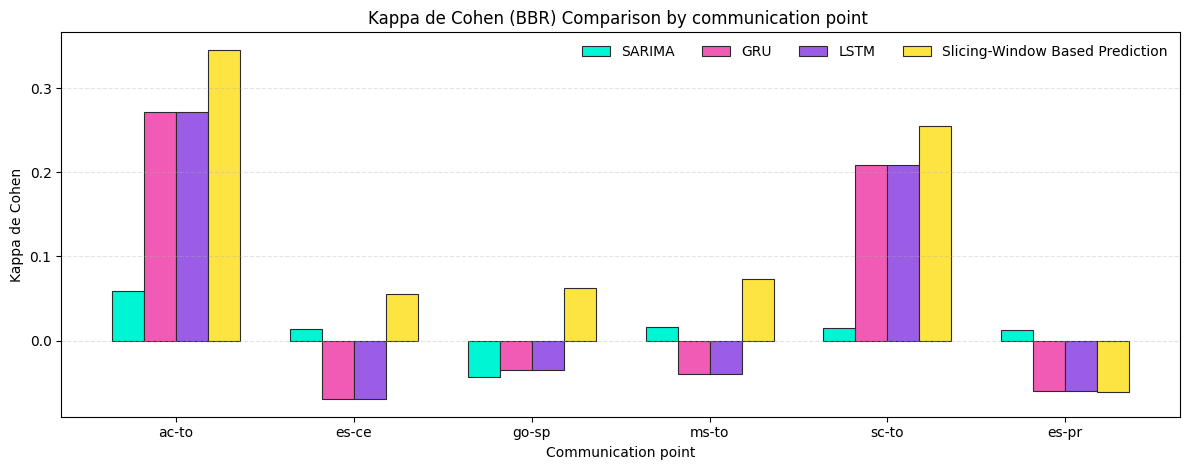

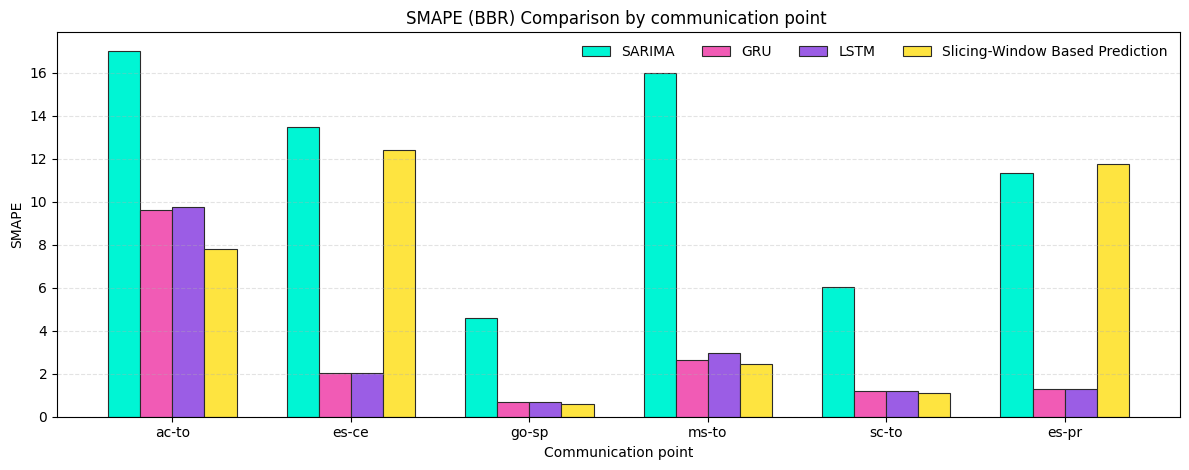

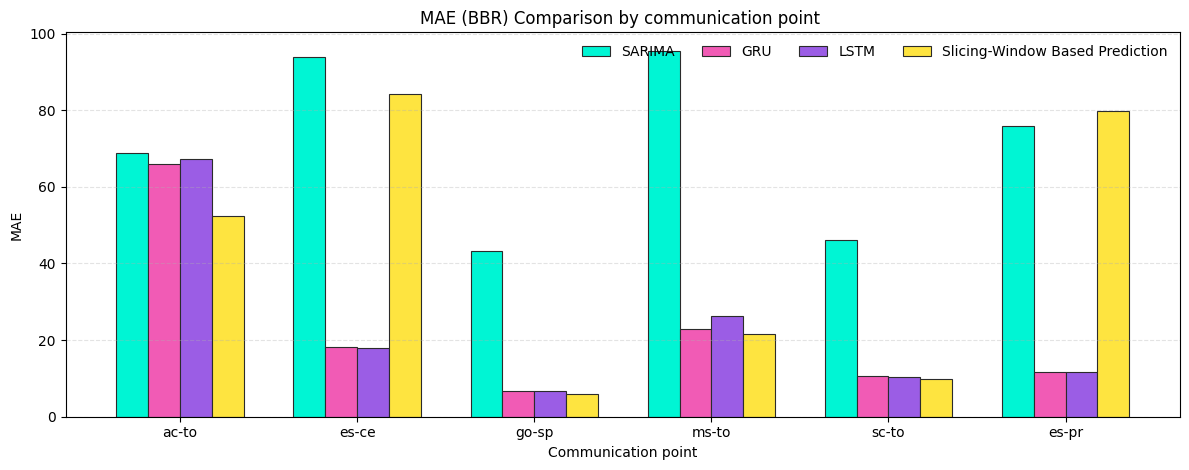

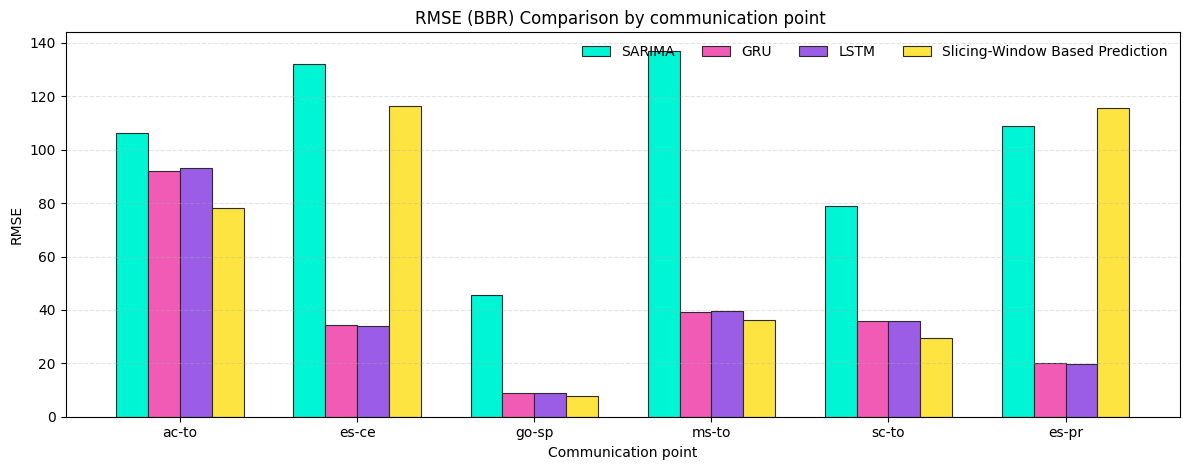

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# =========================
# Config
# =========================
BASE_DIR = Path(".")  # troque para Path("./metrics") se estiverem em outra pasta

FILES = {
    "SARIMA": BASE_DIR / "metrics/metrics_sarima.csv",
    "GRU": BASE_DIR / "metrics/metrics_gru.csv",
    "LSTM": BASE_DIR / "metrics/metrics_lstm.csv",
    "PROPOSAL": BASE_DIR / "metrics/metrics_proposal.csv",
}

POINTS = ["ac-to", "es-ce", "go-sp", "ms-to", "sc-to", "es-pr"]
MODEL_ORDER = ["SARIMA", "GRU", "LSTM", "PROPOSAL"]

MODEL_DISPLAY = {
    "SARIMA": "SARIMA",
    "GRU": "GRU",
    "LSTM": "LSTM",
    "PROPOSAL": "Slicing-Window Based Prediction",
}

METRICS = {
    # "smape": "SMAPE (↓ better)",
    # "mae": "MAE (↓ better)",
    # "rmse": "RMSE (↓ better)",
    # "correncapa": "Kappa de Cohen (↑ better)",
    "smape": "SMAPE",
    "mae": "MAE",
    "rmse": "RMSE",
    "correncapa": "Kappa de Cohen",
}

# cores terrosas (1 por modelo)
EARTHY_MODEL = {
    "SARIMA": "#7F4F24",   # marrom
    "GRU": "#A68A64",      # areia
    "LSTM": "#6B705C",     # oliva acinzentado
    "PROPOSAL": "#CB997E", # terracota clara
}

NEON_MODEL = {
    "SARIMA": "#00E5FF",    # cyan
    "GRU": "#FF2E63",       # neon red/pink
    "LSTM": "#08D9D6",      # bright teal
    "PROPOSAL": "#FFD300",  # vivid yellow
}

NEON_MODEL2 = {
    "SARIMA": "#00F5D4",    # neon turquoise
    "GRU": "#F15BB5",       # neon pink
    "LSTM": "#9B5DE5",      # electric purple
    "PROPOSAL": "#FEE440",  # neon yellow
}

# =========================
# Load + merge
# =========================
missing_files = [fp for fp in FILES.values() if not fp.exists()]
if missing_files:
    raise FileNotFoundError(
        "Não encontrei estes arquivos:\n" +
        "\n".join(str(p.resolve()) for p in missing_files) +
        "\n\n➡️ Ajuste BASE_DIR para a pasta correta."
    )

dfs = []
for model, fp in FILES.items():
    d = pd.read_csv(fp)
    d.columns = [c.strip().lower() for c in d.columns]
    d["model"] = model
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)

# garantir tipos
for col in METRICS.keys():
    df[col] = pd.to_numeric(df[col], errors="coerce")

# filtrar pontos
df = df[df["link"].isin(POINTS)].copy()

# se houver mais de uma linha por (link, model), agrega (média)
df_agg = (
    df.groupby(["link", "model"], as_index=False)
      .agg({m: "mean" for m in METRICS.keys()})
)

# garantir ordem dos eixos
df_agg["link"] = pd.Categorical(df_agg["link"], categories=POINTS, ordered=True)
df_agg["model"] = pd.Categorical(df_agg["model"], categories=MODEL_ORDER, ordered=True)
df_agg = df_agg.sort_values(["link", "model"])

# =========================
# Plot grouped like your image
# =========================
def plot_grouped(metric_col: str, title_suffix: str = "(BBR)"):
    metric_label = METRICS[metric_col]

    # pivot: rows=link, cols=model, values=metric
    pv = df_agg.pivot(index="link", columns="model", values=metric_col).reindex(POINTS)

    x = np.arange(len(POINTS))
    width = 0.18  # barra fina p/ caber 4 modelos

    plt.figure(figsize=(12, 4.8))

    for i, model in enumerate(MODEL_ORDER):
        y = pv[model].values if model in pv.columns else np.full(len(POINTS), np.nan)
        offset = (i - (len(MODEL_ORDER)-1)/2) * width

        plt.bar(
            x + offset, y, width=width,
            label=MODEL_DISPLAY[model],
            color=NEON_MODEL2[model],
            edgecolor="#2b2b2b",
            linewidth=0.8
        )

    plt.xticks(x, POINTS)
    plt.xlabel("Communication point")
    plt.ylabel(metric_label)
    plt.title(f"{metric_label} {title_suffix} Comparison by communication point ")
    plt.grid(True, axis="y", linestyle="--", alpha=0.35)
    plt.legend(ncol=4, frameon=False, loc="upper right")
    plt.tight_layout()
    plt.show()

# Plota as 4 métricas, cada uma em um gráfico (igual estilo do anexo)
for m in ["correncapa", "smape", "mae", "rmse"]:
    plot_grouped(m)








LaTeX wins table (bbr):
\begin{table}
\caption{Win-rate of Proposal over baselines (bbr). Format: wins/points.}
\label{tab:wins_bbr}
\begin{tabular}{llcccc}
\toprule
Protocol & Baseline & SMAPE & MAE & RMSE & Kappa de Cohen \\
\midrule
bbr & SARIMA & 82/132 & 84/132 & 74/132 & 98/132 \\
bbr & GRU & 46/88 & 46/88 & 43/88 & 41/88 \\
bbr & LSTM & 44/88 & 43/88 & 43/88 & 41/88 \\
\bottomrule
\end{tabular}
\end{table}










LaTeX wins table (cubic):
\begin{table}
\caption{Win-rate of Proposal over baselines (cubic). Format: wins/points.}
\label{tab:wins_cubic}
\begin{tabular}{llcccc}
\toprule
Protocol & Baseline & SMAPE & MAE & RMSE & Kappa de Cohen \\
\midrule
cubic & SARIMA & 104/149 & 107/149 & 92/149 & 116/149 \\
cubic & GRU & 0/0 & 0/0 & 0/0 & 0/0 \\
cubic & LSTM & 0/0 & 0/0 & 0/0 & 0/0 \\
\bottomrule
\end{tabular}
\end{table}










LaTeX wins table (ALL):
\begin{table}
\caption{Win-rate of Proposal over baselines (ALL). Format: wins/points.}
\label{tab:wins_ALL}
\begin{tabular}{llcccc}
\toprule
Protocol & Baseline & SMAPE & MAE & RMSE & Kappa de Cohen \\
\midrule
ALL & SARIMA & 119/230 & 139/230 & 129/230 & 179/230 \\
ALL & GRU & 32/88 & 33/88 & 30/88 & 42/88 \\
ALL & LSTM & 31/88 & 30/88 & 32/88 & 41/88 \\
\bottomrule
\end{tabular}
\end{table}



In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# CONFIG
# =========================
BASE_DIR = Path("./metrics")  # ajuste se necessário (ex: Path("./metrics"))

FILES = {
    "SARIMA":   BASE_DIR / "metrics_sarima.csv",
    "GRU":      BASE_DIR / "metrics_gru.csv",
    "LSTM":     BASE_DIR / "metrics_lstm.csv",
    "PROPOSAL": BASE_DIR / "metrics_proposal.csv",
}

# Métricas (coluna -> (nome bonito, direção))
# direction: "min" = menor é melhor, "max" = maior é melhor
METRICS = {
    "smape":     ("SMAPE", "min"),
    "mae":       ("MAE", "min"),
    "rmse":      ("RMSE", "min"),
    "correncapa":("Kappa de Cohen", "max"),
}

BASELINES = ["SARIMA", "GRU", "LSTM"]  # Proposal vs cada baseline
PROPOSAL_KEY = "PROPOSAL"

# Quais protocolos mostrar: separados e/ou juntos
PROTOCOL_MODES = ["bbr", "cubic", "ALL"]  # "ALL" junta tudo

# =========================
# LOAD + MERGE
# =========================
missing_files = [fp for fp in FILES.values() if not fp.exists()]
if missing_files:
    raise FileNotFoundError(
        "Não encontrei estes arquivos:\n" +
        "\n".join(str(p.resolve()) for p in missing_files) +
        "\n\n➡️ Ajuste BASE_DIR para a pasta correta."
    )

dfs = []
for model, fp in FILES.items():
    d = pd.read_csv(fp)
    d.columns = [c.strip().lower() for c in d.columns]
    d["model"] = model
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)

# Tipos numéricos
for col in METRICS.keys():
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Normalização de strings
df["link"] = df["link"].astype(str).str.strip().str.lower()
df["protocol"] = df["protocol"].astype(str).str.strip().str.lower()
df["model"] = df["model"].astype(str).str.strip().str.upper()

# Remove linhas sem métricas
df = df.dropna(subset=list(METRICS.keys()))

# Se existir mais de uma linha por (link, protocol, model), agrega (média)
df = (
    df.groupby(["link", "protocol", "model"], as_index=False)
      .agg({m: "mean" for m in METRICS.keys()})
)

# =========================
# HELPERS
# =========================
def delta_percent(proposal_vals: pd.Series, baseline_vals: pd.Series, direction: str) -> pd.Series:
    """
    Δ% (Proposal vs Baseline)
    - Para métricas de erro (min): (baseline - proposal)/baseline * 100
    - Para métricas de ganho (max, ex Kappa): (proposal - baseline)/abs(baseline) * 100
      (usa abs(baseline) para não explodir sinal e reduzir weirdness quando baseline < 0)
    """
    b = baseline_vals.astype(float)
    p = proposal_vals.astype(float)

    eps = 1e-12
    if direction == "min":
        denom = b.replace(0, np.nan).abs().fillna(np.nan)
        denom = denom.where(denom > eps, np.nan)
        return (b - p) / denom * 100.0
    else:  # "max"
        denom = b.abs().replace(0, np.nan)
        denom = denom.where(denom > eps, np.nan)
        return (p - b) / denom * 100.0

def better(proposal_val: float, baseline_val: float, direction: str) -> bool:
    if pd.isna(proposal_val) or pd.isna(baseline_val):
        return False
    if direction == "min":
        return proposal_val < baseline_val
    else:
        return proposal_val > baseline_val

def make_pivot(protocol_mode: str) -> pd.DataFrame:
    if protocol_mode == "ALL":
        d = df.copy()
        # junta protocolos (média por link+model)
        d = d.groupby(["link", "model"], as_index=False).agg({m: "mean" for m in METRICS.keys()})
        d["protocol"] = "all"
    else:
        d = df[df["protocol"] == protocol_mode].copy()
        d = d.groupby(["link", "protocol", "model"], as_index=False).agg({m: "mean" for m in METRICS.keys()})
    return d

def compute_delta_table(d: pd.DataFrame, baseline: str, protocol_mode: str) -> pd.DataFrame:
    """
    Retorna df_delta com index=link e colunas=metricas (Δ%).
    """
    # pivot por métrica (index link, columns model)
    links = sorted(d["link"].unique().tolist())

    delta_cols = {}
    for metric_col, (metric_name, direction) in METRICS.items():
        pv = d.pivot_table(index="link", columns="model", values=metric_col, aggfunc="mean")
        if PROPOSAL_KEY not in pv.columns or baseline not in pv.columns:
            # se faltar, preenche NaNs
            delta_cols[metric_name] = pd.Series(index=links, data=np.nan)
            continue

        # garante alinhamento nos links
        p = pv[PROPOSAL_KEY].reindex(links)
        b = pv[baseline].reindex(links)
        delta_cols[metric_name] = delta_percent(p, b, direction)

    df_delta = pd.DataFrame(delta_cols, index=links)
    df_delta.index.name = "communication_point"
    df_delta.attrs["baseline"] = baseline
    df_delta.attrs["protocol_mode"] = protocol_mode
    return df_delta

def plot_heatmap(df_delta: pd.DataFrame, title: str):
    """
    Heatmap simples sem seaborn: imshow + valores.
    """
    data = df_delta.values.astype(float)

    # limites simétricos (melhor estética para Δ%)
    finite = np.isfinite(data)
    if finite.any():
        vmax = np.nanpercentile(np.abs(data[finite]), 95)  # robusto contra outliers
        vmax = max(vmax, 1e-6)
    else:
        vmax = 1.0
    vmin = -vmax

    fig, ax = plt.subplots(figsize=(10.5, max(3.8, 0.28 * df_delta.shape[0] + 1.5)))
    im = ax.imshow(data, aspect="auto", vmin=vmin, vmax=vmax, cmap="coolwarm")

    ax.set_title(title, pad=12)
    ax.set_xlabel("Metric")
    ax.set_ylabel("Communication point")

    ax.set_xticks(np.arange(df_delta.shape[1]))
    ax.set_xticklabels(df_delta.columns.tolist(), rotation=20, ha="right")

    ax.set_yticks(np.arange(df_delta.shape[0]))
    ax.set_yticklabels(df_delta.index.tolist())

    # anotar valores (opcional; pode ficar pesado se muitos links)
    if df_delta.shape[0] <= 30:
        for i in range(df_delta.shape[0]):
            for j in range(df_delta.shape[1]):
                val = data[i, j]
                if np.isfinite(val):
                    ax.text(j, i, f"{val:.1f}%", ha="center", va="center", fontsize=8, color="black")

    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("Δ% (Proposal vs Baseline)")

    plt.tight_layout()
    plt.show()

def wins_latex_table(d: pd.DataFrame, protocol_mode: str) -> str:
    """
    Tabela de vitórias do Proposal:
    - wins_vs_<baseline> por métrica: quantos pontos Proposal foi melhor que baseline
    - total_points: quantos pontos avaliados (que têm Proposal + baseline)
    """
    rows = []
    links = sorted(d["link"].unique().tolist())

    # pivots por métrica
    pivots = {
        metric_col: d.pivot_table(index="link", columns="model", values=metric_col, aggfunc="mean")
        for metric_col in METRICS.keys()
    }

    for baseline in BASELINES:
        row = {"Baseline": baseline, "Protocol": protocol_mode}
        total_pts = 0

        # calcular total pontos comparáveis (tem proposal e baseline em TODAS as métricas?)
        # (mais rigoroso: exige existência de proposal+baseline para a métrica analisada)
        # Aqui: total_pts = pontos onde existe proposal e baseline para pelo menos uma métrica (usaremos por métrica abaixo).
        # Vamos computar total por métrica também.
        for metric_col, (metric_name, direction) in METRICS.items():
            pv = pivots[metric_col]
            if PROPOSAL_KEY not in pv.columns or baseline not in pv.columns:
                row[metric_name] = "0/0"
                continue

            comp = pv[[PROPOSAL_KEY, baseline]].dropna()
            n = len(comp)
            w = sum(better(comp.loc[idx, PROPOSAL_KEY], comp.loc[idx, baseline], direction) for idx in comp.index)

            row[metric_name] = f"{w}/{n}"
        rows.append(row)

    wins_df = pd.DataFrame(rows)

    # Ordena colunas
    ordered_cols = ["Protocol", "Baseline"] + [METRICS[m][0] for m in METRICS.keys()]
    wins_df = wins_df[ordered_cols]

    latex = wins_df.to_latex(
        index=False,
        escape=False,
        column_format="ll" + "c"*len(METRICS),
        caption=f"Win-rate of Proposal over baselines ({protocol_mode}). Format: wins/points.",
        label=f"tab:wins_{protocol_mode}".replace("-", "_")
    )
    return latex

# =========================
# RUN: heatmaps + latex wins
# =========================
for protocol_mode in PROTOCOL_MODES:
    dprot = make_pivot(protocol_mode)
    if dprot.empty:
        print(f"⚠️ Sem dados para protocolo: {protocol_mode}")
        continue

    # Heatmaps: Proposal vs cada baseline
    for baseline in BASELINES:
        df_delta = compute_delta_table(dprot, baseline=baseline, protocol_mode=protocol_mode)

        title = f"Δ% Heatmap — Proposal vs {baseline} ({protocol_mode.upper()})"
        plot_heatmap(df_delta, title=title)

    # LaTeX wins table
    latex = wins_latex_table(dprot, protocol_mode=protocol_mode)
    print("\n" + "="*80)
    print(f"LaTeX wins table ({protocol_mode}):")
    print("="*80)
    print(latex)